In [ ]:
!pip install biopython pandas numpy scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 15.4 MB/s  0:00:00


In [ ]:
import gzip
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Bio import SeqIO
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 9606.protein.sequences.v12.5.fa.gz to 9606.protein.sequences.v12.5.fa.gz
Saving 9606.protein.links.v12.5.txt.gz to 9606.protein.links.v12.5.txt.gz


In [ ]:
from Bio import SeqIO
import gzip

sequence_file = "9606.protein.sequences.v12.5.fa.gz"

sequences = {}

with gzip.open(sequence_file, "rt") as handle:
    for record in SeqIO.parse(handle, "fasta"):
        protein_id = record.id
        sequence = str(record.seq)

        sequences[protein_id] = sequence

print("Total protein sequences:", len(sequences))

# Display first 5 proteins
for protein_id, sequence in list(sequences.items())[:5]:
    print(protein_id, sequence[:50])

Total protein sequences: 19699
9606.ENSP00000000233 MGLTVSALFSRIFGKKQMRILMVGLDAAGKTTILYKLKLGEIVTTIPTIG
9606.ENSP00000000412 MFPFYSCWRTGLLLLLLAVAVRESWQTEEKTCDLVGEKGKESEKELALVK
9606.ENSP00000001008 MTAEEMKATESGAQSAPLPMEGVDISPKQDEGVLKVIKREGTGTEMPMIG
9606.ENSP00000001146 MLFEGLDLVSALATLAACLVSVTLLLAVSQQLWQLRWAATRDKSCKLPIP
9606.ENSP00000002125 MSVLLRSGLGPLCAVARAAIPFIWRGKYFSSGNEPAENPVTPMLRHLMYK


In [ ]:
links_file = "9606.protein.links.v12.5.txt.gz"

links = pd.read_csv(
    links_file,
    sep=" ",
    compression="gzip"
)

print("Total interaction records:", len(links))

display(links.head())

print("\nColumn names:")
print(links.columns.tolist())

Total interaction records: 10826054


,protein1,protein2,combined_score
0,9606.ENSP00000000233,9606.ENSP00000000412,200
1,9606.ENSP00000000233,9606.ENSP00000037243,178
2,9606.ENSP00000000233,9606.ENSP00000040663,226
3,9606.ENSP00000000233,9606.ENSP00000046087,158
4,9606.ENSP00000000233,9606.ENSP00000054666,415



Column names:
['protein1', 'protein2', 'combined_score']


In [ ]:
print("SEQUENCE DATASET")
print("Total proteins:", len(sequences))

print("\nINTERACTION DATASET")
print(links.info())

print("\nMissing values:")
print(links.isnull().sum())

print("\nScore statistics:")
print(links["combined_score"].describe())

SEQUENCE DATASET
Total proteins: 19699

INTERACTION DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10826054 entries, 0 to 10826053
Data columns (total 3 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   protein1        object
 1   protein2        object
 2   combined_score  int64 
dtypes: int64(1), object(2)
memory usage: 247.8+ MB
None

Missing values:
protein1          0
protein2          0
combined_score    0
dtype: int64

Score statistics:
count    1.082605e+07
mean     3.012458e+02
std      1.784334e+02
min      1.500000e+02
25%      1.840000e+02
50%      2.320000e+02
75%      3.500000e+02
max      9.990000e+02
Name: combined_score, dtype: float64


In [ ]:
# Unique protein IDs in interaction dataset

link_proteins = set(links["protein1"].unique()) | \
                set(links["protein2"].unique())

sequence_proteins = set(sequences.keys())

# Matching and unmatched IDs

matching = link_proteins.intersection(sequence_proteins)

missing_sequences = link_proteins - sequence_proteins

print("Unique proteins in interaction dataset:",
      len(link_proteins))

print("Proteins in sequence dataset:",
      len(sequence_proteins))

print("Matching protein IDs:",
      len(matching))

print("IDs without sequences:",
      len(missing_sequences))

print("\nFirst 5 matching IDs:")
print(list(matching)[:5])

Unique proteins in interaction dataset: 19649
Proteins in sequence dataset: 19699
Matching protein IDs: 19649
IDs without sequences: 0

First 5 matching IDs:
['9606.ENSP00000333358', '9606.ENSP00000354525', '9606.ENSP00000259818', '9606.ENSP00000268711', '9606.ENSP00000481021']


In [ ]:
# STEP 3A: Prepare positive interaction candidates

# Remove self-interactions
positive_candidates = links[
    links["protein1"] != links["protein2"]
].copy()

# Standardize undirected protein pairs
positive_candidates["protein_A"] = positive_candidates[
    ["protein1", "protein2"]
].min(axis=1)

positive_candidates["protein_B"] = positive_candidates[
    ["protein1", "protein2"]
].max(axis=1)

# Remove duplicate pairs, retaining highest score
positive_candidates = (
    positive_candidates
    .sort_values("combined_score", ascending=False)
    .drop_duplicates(
        subset=["protein_A", "protein_B"]
    )
)

# Apply confidence threshold
positive_candidates = positive_candidates[
    positive_candidates["combined_score"] >= 700
].copy()

positive_candidates["label"] = 1

print("High-confidence unique positive pairs:",
      len(positive_candidates))

print("\nScore statistics:")
print(positive_candidates["combined_score"].describe())

print("\nFirst five positive pairs:")
print(positive_candidates.head())

High-confidence unique positive pairs: 282864

Score statistics:
count    282864.000000
mean        865.615175
std          93.260937
min         700.000000
25%         790.000000
50%         871.000000
75%         948.000000
max         999.000000
Name: combined_score, dtype: float64

First five positive pairs:
                     protein1              protein2  combined_score  \
6190749  9606.ENSP00000360242  9606.ENSP00000311032             999   
9626959  9606.ENSP00000449328  9606.ENSP00000355315             999   
7654291  9606.ENSP00000378974  9606.ENSP00000264110             999   
2714974  9606.ENSP00000293328  9606.ENSP00000371067             999   
7654360  9606.ENSP00000378974  9606.ENSP00000269305             999   

                    protein_A             protein_B  label  
6190749  9606.ENSP00000311032  9606.ENSP00000360242      1  
9626959  9606.ENSP00000355315  9606.ENSP00000449328      1  
7654291  9606.ENSP00000264110  9606.ENSP00000378974      1  
2714974  9606.E

In [ ]:
from sklearn.model_selection import train_test_split

# Use proteins present in both datasets
protein_ids = sorted(matching)

# 70% training, 30% temporary
train_proteins, temp_proteins = train_test_split(
    protein_ids,
    test_size=0.30,
    random_state=42
)

# Divide remaining 30% equally
val_proteins, test_proteins = train_test_split(
    temp_proteins,
    test_size=0.50,
    random_state=42
)

# Count positive pairs entirely within each group
def count_positive_pairs(proteins):
    protein_set = set(proteins)

    return (
        positive_candidates["protein_A"].isin(protein_set)
        & positive_candidates["protein_B"].isin(protein_set)
    ).sum()

print("Training proteins:", len(train_proteins))
print("Validation proteins:", len(val_proteins))
print("Testing proteins:", len(test_proteins))

print("\nHigh-confidence positive pairs available:")
print("Training:", count_positive_pairs(train_proteins))
print("Validation:", count_positive_pairs(val_proteins))
print("Testing:", count_positive_pairs(test_proteins))

Training proteins: 13754
Validation proteins: 2947
Testing proteins: 2948

High-confidence positive pairs available:
Training: 135632
Validation: 7269
Testing: 6138


In [ ]:
# STEP 4: Generate balanced training, validation and test datasets

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Target positive samples per split
sample_sizes = {
    "train": 7000,
    "validation": 1500,
    "test": 1500
}

protein_groups = {
    "train": train_proteins,
    "validation": val_proteins,
    "test": test_proteins
}

# 1. Select positive samples within each protein split
positive_sets = {}

for name, size in sample_sizes.items():

    group = set(protein_groups[name])

    available = positive_candidates[
        positive_candidates["protein_A"].isin(group)
        & positive_candidates["protein_B"].isin(group)
    ]

    positive_sets[name] = available.sample(
        n=size,
        random_state=42
    )[["protein_A", "protein_B"]].copy()

    positive_sets[name]["label"] = 1

# 2. Create numeric IDs for efficient pair checking
protein_ids = sorted(matching)

id_to_idx = {
    protein: i for i, protein in enumerate(protein_ids)
}

n = len(protein_ids)

# Encode ALL observed STRING pairs, regardless of score
a = links["protein1"].map(id_to_idx).to_numpy(dtype=np.int64)
b = links["protein2"].map(id_to_idx).to_numpy(dtype=np.int64)

observed_keys = np.unique(
    np.minimum(a, b) * n + np.maximum(a, b)
)

print("Unique observed STRING pairs:", len(observed_keys))

# 3. Generate absent pairs within each protein group
def generate_negatives(proteins, count):

    indices = np.array(
        [id_to_idx[p] for p in proteins],
        dtype=np.int64
    )

    accepted = set()

    while len(accepted) < count:

        batch_size = max(10000, (count - len(accepted)) * 3)

        x = rng.choice(indices, batch_size)
        y = rng.choice(indices, batch_size)

        valid = x != y
        x, y = x[valid], y[valid]

        keys = np.minimum(x, y) * n + np.maximum(x, y)
        keys = np.unique(keys)

        # Reject every pair found in the original STRING links
        positions = np.searchsorted(observed_keys, keys)

        in_range = positions < len(observed_keys)

        is_observed = np.zeros(len(keys), dtype=bool)

        is_observed[in_range] = (
            observed_keys[positions[in_range]] == keys[in_range]
        )

        for key in keys[~is_observed]:
            accepted.add(int(key))

            if len(accepted) == count:
                break

    pairs = [divmod(key, n) for key in accepted]

    return pd.DataFrame({
        "protein_A": [protein_ids[x] for x, y in pairs],
        "protein_B": [protein_ids[y] for x, y in pairs],
        "label": 0
    })

# 4. Create each split independently
datasets = {}

for name, size in sample_sizes.items():

    negatives = generate_negatives(
        protein_groups[name],
        size
    )

    combined = pd.concat(
        [positive_sets[name], negatives],
        ignore_index=True
    )

    datasets[name] = combined.sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

# 5. Verify results
for name, data in datasets.items():

    print(f"\n{name.upper()} DATASET")
    print("Total samples:", len(data))
    print("Positive:", (data["label"] == 1).sum())
    print("Negative:", (data["label"] == 0).sum())

# 6. Save datasets
datasets["train"].to_csv("ppi_train.csv", index=False)
datasets["validation"].to_csv("ppi_validation.csv", index=False)
datasets["test"].to_csv("ppi_test.csv", index=False)

print("\nAll three datasets created successfully!")

Unique observed STRING pairs: 5413027

TRAIN DATASET
Total samples: 14000
Positive: 7000
Negative: 7000

VALIDATION DATASET
Total samples: 3000
Positive: 1500
Negative: 1500

TEST DATASET
Total samples: 3000
Positive: 1500
Negative: 1500

All three datasets created successfully!


In [ ]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from collections import Counter

# 20 standard amino acids
AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"

def extract_protein_features(sequence):

    sequence = sequence.upper()

    # Keep standard amino acids for calculations
    clean_seq = ''.join(
        aa for aa in sequence if aa in AMINO_ACIDS
    )

    if len(clean_seq) < 5:
        return None

    analysis = ProteinAnalysis(clean_seq)

    # Amino acid composition
    counts = Counter(clean_seq)

    features = {}

    for aa in AMINO_ACIDS:
        features[f"AAC_{aa}"] = (
            counts[aa] / len(clean_seq)
        )

    # Additional biological features
    features["sequence_length"] = len(clean_seq)

    features["molecular_weight"] = (
        analysis.molecular_weight()
    )

    features["hydrophobicity"] = analysis.gravy()

    return features


# Collect proteins used in our three datasets
all_pairs = pd.concat([
    datasets["train"],
    datasets["validation"],
    datasets["test"]
])

used_proteins = set(all_pairs["protein_A"]) | \
                set(all_pairs["protein_B"])

# Extract features once per protein
protein_features = {}

skipped = 0

for protein_id in used_proteins:

    sequence = sequences.get(protein_id)

    if sequence is None:
        skipped += 1
        continue

    features = extract_protein_features(sequence)

    if features is None:
        skipped += 1
        continue

    protein_features[protein_id] = features


# Convert to DataFrame
protein_feature_df = pd.DataFrame.from_dict(
    protein_features,
    orient="index"
)

print("Total proteins used:", len(used_proteins))
print("Successfully extracted:", len(protein_feature_df))
print("Skipped proteins:", skipped)

print("\nIndividual feature count:",
      len(protein_feature_df.columns))

print("\nFeature names:")
print(protein_feature_df.columns.tolist())

print("\nFirst five proteins:")
display(protein_feature_df.head())

Total proteins used: 13917
Successfully extracted: 13917
Skipped proteins: 0

Individual feature count: 23

Feature names:
['AAC_A', 'AAC_C', 'AAC_D', 'AAC_E', 'AAC_F', 'AAC_G', 'AAC_H', 'AAC_I', 'AAC_K', 'AAC_L', 'AAC_M', 'AAC_N', 'AAC_P', 'AAC_Q', 'AAC_R', 'AAC_S', 'AAC_T', 'AAC_V', 'AAC_W', 'AAC_Y', 'sequence_length', 'molecular_weight', 'hydrophobicity']

First five proteins:


,AAC_A,AAC_C,AAC_D,AAC_E,AAC_F,AAC_G,AAC_H,AAC_I,AAC_K,AAC_L,...,AAC_Q,AAC_R,AAC_S,AAC_T,AAC_V,AAC_W,AAC_Y,sequence_length,molecular_weight,hydrophobicity
9606.ENSP00000268711,0.068493,0.013699,0.041096,0.075342,0.020548,0.020548,0.020548,0.034247,0.068493,0.095890,...,0.116438,0.047945,0.075342,0.027397,0.041096,0.000000,0.013699,146,16402.6037,-0.845890
9606.ENSP00000481021,0.093220,0.067797,0.025424,0.042373,0.016949,0.067797,0.042373,0.042373,0.042373,0.076271,...,0.042373,0.084746,0.093220,0.042373,0.042373,0.016949,0.016949,118,12924.7336,-0.428814
9606.ENSP00000379140,0.114286,0.050000,0.021429,0.035714,0.014286,0.028571,0.021429,0.050000,0.064286,0.121429,...,0.021429,0.071429,0.057143,0.021429,0.092857,0.028571,0.014286,140,15495.1939,0.043571
9606.ENSP00000483328,0.052174,0.017391,0.043478,0.078261,0.060870,0.026087,0.026087,0.086957,0.069565,0.147826,...,0.034783,0.034783,0.043478,0.078261,0.034783,0.000000,0.017391,115,13074.0687,-0.080000
9606.ENSP00000288078,0.101476,0.025830,0.044280,0.061808,0.025830,0.096863,0.031365,0.023985,0.018450,0.138376,...,0.052583,0.066421,0.057196,0.044280,0.081181,0.021218,0.020295,1084,117621.4729,-0.004336


In [ ]:
# STEP 5B: Pairwise feature construction

feature_columns = protein_feature_df.columns.tolist()

def create_pair_features(data):

    features_A = protein_feature_df.loc[
        data["protein_A"]
    ].to_numpy(dtype=np.float32)

    features_B = protein_feature_df.loc[
        data["protein_B"]
    ].to_numpy(dtype=np.float32)

    # Absolute difference
    difference = np.abs(features_A - features_B)

    # Element-wise product
    product = features_A * features_B

    # Combine both
    pair_features = np.concatenate(
        [difference, product],
        axis=1
    )

    column_names = (
        [f"DIFF_{c}" for c in feature_columns] +
        [f"PRODUCT_{c}" for c in feature_columns]
    )

    return pd.DataFrame(
        pair_features,
        columns=column_names
    )


# Create feature matrices
X_train = create_pair_features(datasets["train"])
X_val = create_pair_features(datasets["validation"])
X_test = create_pair_features(datasets["test"])

# Extract labels
y_train = datasets["train"]["label"].to_numpy()
y_val = datasets["validation"]["label"].to_numpy()
y_test = datasets["test"]["label"].to_numpy()

print("TRAIN:", X_train.shape)
print("VALIDATION:", X_val.shape)
print("TEST:", X_test.shape)

print("\nNumber of pairwise features:",
      X_train.shape[1])

display(X_train.head())

TRAIN: (14000, 46)
VALIDATION: (3000, 46)
TEST: (3000, 46)

Number of pairwise features: 46


,DIFF_AAC_A,DIFF_AAC_C,DIFF_AAC_D,DIFF_AAC_E,DIFF_AAC_F,DIFF_AAC_G,DIFF_AAC_H,DIFF_AAC_I,DIFF_AAC_K,DIFF_AAC_L,...,PRODUCT_AAC_Q,PRODUCT_AAC_R,PRODUCT_AAC_S,PRODUCT_AAC_T,PRODUCT_AAC_V,PRODUCT_AAC_W,PRODUCT_AAC_Y,PRODUCT_sequence_length,PRODUCT_molecular_weight,PRODUCT_hydrophobicity
0,0.046461,0.002660,0.072311,0.019129,0.046309,0.007998,0.015549,0.038909,0.066991,0.022351,...,0.004659,0.002571,0.005534,0.000723,0.005374,0.000000,0.000268,112030.0,1.408775e+09,0.223702
1,0.023445,0.019347,0.000165,0.007147,0.008449,0.000908,0.009841,0.016406,0.008374,0.030752,...,0.001630,0.006269,0.009385,0.000970,0.001694,0.000163,0.000232,1113658.0,1.309909e+10,0.485094
2,0.011211,0.000296,0.001148,0.045126,0.010931,0.016824,0.000897,0.021610,0.049645,0.036315,...,0.001869,0.002654,0.004954,0.002141,0.003296,0.000085,0.000639,588620.0,7.429092e+09,-0.057888
3,0.052337,0.003028,0.026169,0.012191,0.020345,0.005125,0.010017,0.016695,0.058938,0.004504,...,0.000311,0.003494,0.009435,0.000505,0.007882,0.000078,0.002795,25756.0,3.239033e+08,0.013211
4,0.027357,0.019226,0.041900,0.032482,0.028728,0.011187,0.011486,0.014874,0.003679,0.011869,...,0.001626,0.001140,0.005273,0.003906,0.003730,0.000255,0.001347,250908.0,3.227863e+09,0.097139


In [ ]:
print("Missing values:", X_train.isnull().sum().sum())
print("Infinite values:", np.isinf(X_train).sum().sum())

print("\nTraining labels:")
print(pd.Series(y_train).value_counts())

print("\nValidation labels:")
print(pd.Series(y_val).value_counts())

print("\nTesting labels:")
print(pd.Series(y_test).value_counts())

Missing values: 0
Infinite values: 0

Training labels:
1    7000
0    7000
Name: count, dtype: int64

Validation labels:
0    1500
1    1500
Name: count, dtype: int64

Testing labels:
0    1500
1    1500
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

# 1. Replace any extreme numerical values if necessary
X_train = X_train.replace(
    [np.inf, -np.inf], np.nan
)

X_val = X_val.replace(
    [np.inf, -np.inf], np.nan
)

X_test = X_test.replace(
    [np.inf, -np.inf], np.nan
)

# 2. Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 3. Feature selection
selector = SelectKBest(
    score_func=f_classif,
    k=30
)

X_train_selected = selector.fit_transform(
    X_train_scaled, y_train
)

X_val_selected = selector.transform(
    X_val_scaled
)

X_test_selected = selector.transform(
    X_test_scaled
)

print("Original features:", X_train.shape[1])
print("Selected features:", X_train_selected.shape[1])

print("Training shape:", X_train_selected.shape)
print("Validation shape:", X_val_selected.shape)
print("Testing shape:", X_test_selected.shape)

print("\nSelected feature names:")

selected_features = X_train.columns[
    selector.get_support()
]

print(selected_features.tolist())

Original features: 46
Selected features: 30
Training shape: (14000, 30)
Validation shape: (3000, 30)
Testing shape: (3000, 30)

Selected feature names:
['DIFF_AAC_A', 'DIFF_AAC_C', 'DIFF_AAC_D', 'DIFF_AAC_E', 'DIFF_AAC_F', 'DIFF_AAC_H', 'DIFF_AAC_I', 'DIFF_AAC_L', 'DIFF_AAC_N', 'DIFF_AAC_P', 'DIFF_AAC_V', 'DIFF_AAC_W', 'DIFF_AAC_Y', 'DIFF_hydrophobicity', 'PRODUCT_AAC_D', 'PRODUCT_AAC_E', 'PRODUCT_AAC_F', 'PRODUCT_AAC_H', 'PRODUCT_AAC_I', 'PRODUCT_AAC_K', 'PRODUCT_AAC_L', 'PRODUCT_AAC_M', 'PRODUCT_AAC_N', 'PRODUCT_AAC_P', 'PRODUCT_AAC_R', 'PRODUCT_AAC_S', 'PRODUCT_AAC_W', 'PRODUCT_sequence_length', 'PRODUCT_molecular_weight', 'PRODUCT_hydrophobicity']


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Define three models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    )
}

# Train and validate
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train_selected, y_train)

    val_predictions = model.predict(X_val_selected)

    print("Validation accuracy:",
          accuracy_score(y_val, val_predictions))

    trained_models[name] = model

print("\nAll three models trained successfully!")


Training: Logistic Regression
Validation accuracy: 0.6953333333333334

Training: Random Forest
Validation accuracy: 0.6956666666666667

Training: SVM
Validation accuracy: 0.7026666666666667

All three models trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in trained_models.items():

    predictions = model.predict(X_val_selected)

    probabilities = model.predict_proba(
        X_val_selected
    )[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

    print("\n", name)
    print(classification_report(y_val, predictions))

    print("Confusion Matrix:")
    print(confusion_matrix(y_val, predictions))

results_df = pd.DataFrame(results)

print("\nFINAL VALIDATION COMPARISON")
display(results_df.round(4))


 Logistic Regression
              precision    recall  f1-score   support

           0       0.69      0.70      0.70      1500
           1       0.70      0.69      0.69      1500

    accuracy                           0.70      3000
   macro avg       0.70      0.70      0.70      3000
weighted avg       0.70      0.70      0.70      3000

Confusion Matrix:
[[1056  444]
 [ 470 1030]]

 Random Forest
              precision    recall  f1-score   support

           0       0.69      0.72      0.70      1500
           1       0.71      0.67      0.69      1500

    accuracy                           0.70      3000
   macro avg       0.70      0.70      0.70      3000
weighted avg       0.70      0.70      0.70      3000

Confusion Matrix:
[[1086  414]
 [ 499 1001]]

 SVM
              precision    recall  f1-score   support

           0       0.69      0.74      0.71      1500
           1       0.72      0.66      0.69      1500

    accuracy                           0.70     

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6953,0.6988,0.6867,0.6927,0.7656
1,Random Forest,0.6957,0.7074,0.6673,0.6868,0.7776
2,SVM,0.7027,0.7213,0.6607,0.6896,0.7643



 Logistic Regression
              precision    recall  f1-score   support

           0       0.66      0.71      0.69      1500
           1       0.69      0.64      0.66      1500

    accuracy                           0.68      3000
   macro avg       0.68      0.68      0.68      3000
weighted avg       0.68      0.68      0.68      3000


 Random Forest
              precision    recall  f1-score   support

           0       0.67      0.75      0.70      1500
           1       0.71      0.63      0.67      1500

    accuracy                           0.69      3000
   macro avg       0.69      0.69      0.68      3000
weighted avg       0.69      0.69      0.68      3000


 SVM
              precision    recall  f1-score   support

           0       0.65      0.75      0.70      1500
           1       0.70      0.60      0.65      1500

    accuracy                           0.68      3000
   macro avg       0.68      0.68      0.67      3000
weighted avg       0.68      0

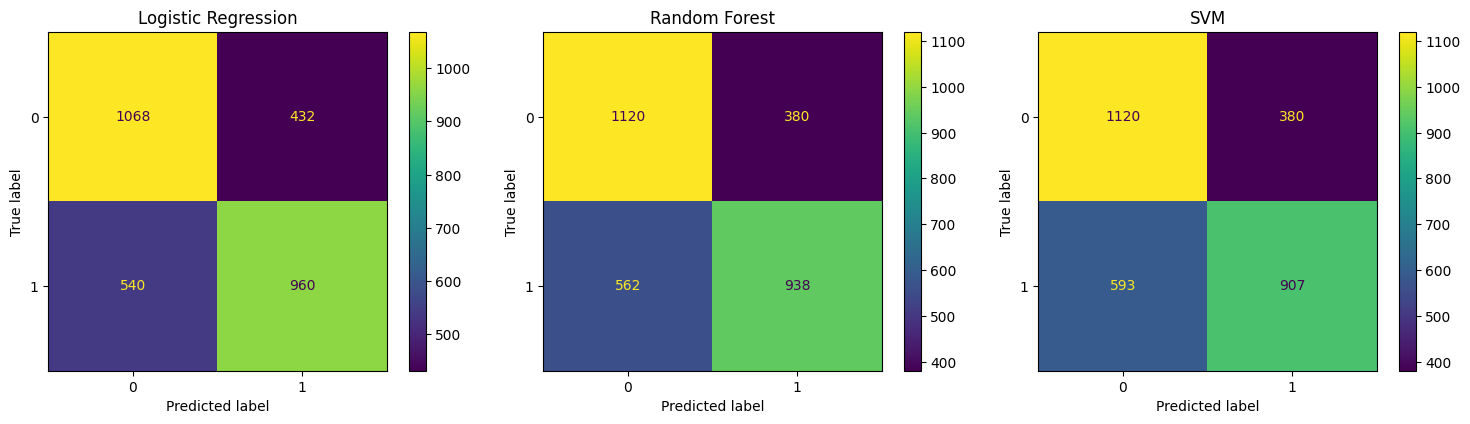


FINAL TEST PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6760,0.6897,0.6400,0.6639,0.7431
1,Random Forest,0.6860,0.7117,0.6253,0.6657,0.7621
2,SVM,0.6757,0.7047,0.6047,0.6509,0.7397


In [ ]:
# STEP 8: FINAL TEST EVALUATION

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

import matplotlib.pyplot as plt

test_results = []

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, trained_models.items()):

    predictions = model.predict(X_test_selected)
    probabilities = model.predict_proba(
        X_test_selected
    )[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    print("\n", name)
    print(classification_report(y_test, predictions))

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Final comparison
test_results_df = pd.DataFrame(test_results)

print("\nFINAL TEST PERFORMANCE")
display(test_results_df.round(4))

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Hyperparameter search spaces

param_grids = {

    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10, 100]
    },

    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [10, 15, 20, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    },

    "SVM": {
        "C": [0.1, 1, 10],
        "gamma": ["scale", 0.01, 0.1],
        "kernel": ["rbf", "linear"]
    }
}

base_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        random_state=42
    )
}

best_models = {}

for name, model in base_models.items():

    print("\nTuning:", name)

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grids[name],
        n_iter=8,
        scoring="roc_auc",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train_selected, y_train)

    best_models[name] = search.best_estimator_

    print("Best parameters:", search.best_params_)
    print("Best CV ROC-AUC:", search.best_score_)

print("\nALL THREE MODELS TUNED!")


Tuning: Logistic Regression
Fitting 3 folds for each of 5 candidates, totalling 15 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 5 is smaller than n_iter=8. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best parameters: {'C': 100}
Best CV ROC-AUC: 0.7316981188460557

Tuning: Random Forest
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
Best CV ROC-AUC: 0.7628749179106342

Tuning: SVM
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'kernel': 'rbf', 'gamma': 0.01, 'C': 1}
Best CV ROC-AUC: 0.7553186557410528

ALL THREE MODELS TUNED!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

tuned_results = []

for name, model in best_models.items():

    predictions = model.predict(X_val_selected)

    # Handle SVM and other models correctly
    if hasattr(model, "predict_proba") and (
        model.__class__.__name__ != "SVC"
        or model.probability
    ):
        scores = model.predict_proba(
            X_val_selected
        )[:, 1]

    else:
        scores = model.decision_function(
            X_val_selected
        )

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, scores)
    })

tuned_results_df = pd.DataFrame(tuned_results)

print("TUNED MODEL VALIDATION RESULTS")

display(tuned_results_df.round(4))

TUNED MODEL VALIDATION RESULTS


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6917,0.6960,0.6807,0.6882,0.7651
1,Random Forest,0.7030,0.7173,0.6700,0.6929,0.7782
2,SVM,0.7017,0.7181,0.6640,0.6900,0.7713


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

def get_scores(model, X):
    if hasattr(model, "predict_proba") and (
        model.__class__.__name__ != "SVC"
        or model.probability
    ):
        return model.predict_proba(X)[:, 1]

    return model.decision_function(X)


final_comparison = []

all_models = {
    **{"Original " + k: v for k, v in trained_models.items()},
    **{"Tuned " + k: v for k, v in best_models.items()}
}

for name, model in all_models.items():

    pred = model.predict(X_test_selected)
    scores = get_scores(model, X_test_selected)

    final_comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

final_comparison_df = pd.DataFrame(final_comparison)

display(final_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original Logistic Regression,0.6760,0.6897,0.6400,0.6639,0.7431
1,Original Random Forest,0.6860,0.7117,0.6253,0.6657,0.7621
2,Original SVM,0.6757,0.7047,0.6047,0.6509,0.7397
3,Tuned Logistic Regression,0.6713,0.6844,0.6360,0.6593,0.7429
4,Tuned Random Forest,0.6917,0.7154,0.6367,0.6737,0.7602
5,Tuned SVM,0.6910,0.7272,0.6113,0.6643,0.7578


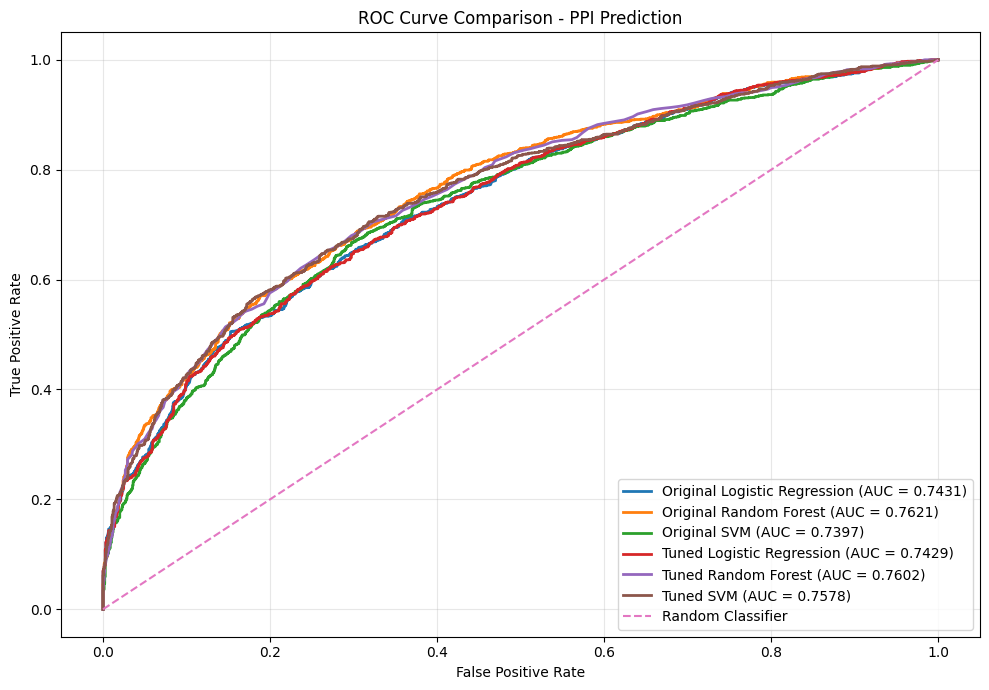

In [ ]:
# STEP 10: ROC CURVE COMPARISON

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Combine original and tuned models
all_models = {
    **{"Original " + name: model
       for name, model in trained_models.items()},

    **{"Tuned " + name: model
       for name, model in best_models.items()}
}

plt.figure(figsize=(10, 7))

for name, model in all_models.items():

    # Get prediction scores
    if hasattr(model, "predict_proba") and (
        model.__class__.__name__ != "SVC"
        or model.probability
    ):
        y_scores = model.predict_proba(
            X_test_selected
        )[:, 1]

    else:
        y_scores = model.decision_function(
            X_test_selected
        )

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_test, y_scores
    )

    # Calculate AUC
    auc_value = roc_auc_score(
        y_test, y_scores
    )

    # Plot
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison - PPI Prediction")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Check which feature-selection variables exist
print("Feature selection variables:")

for name in globals():
    if "select" in name.lower() or "feature" in name.lower():
        print(name)

Feature selection variables:
SelectKBest
extract_protein_features
protein_features
features
protein_feature_df
feature_columns
create_pair_features
selector
X_train_selected
X_val_selected
X_test_selected
selected_features


In [ ]:
print("Selected features type:", type(selected_features))
print("Number of selected features:", len(selected_features))
print("\nSelected feature names:")
print(selected_features)

Selected features type: <class 'pandas.core.indexes.base.Index'>
Number of selected features: 30

Selected feature names:
Index(['DIFF_AAC_A', 'DIFF_AAC_C', 'DIFF_AAC_D', 'DIFF_AAC_E', 'DIFF_AAC_F',
       'DIFF_AAC_H', 'DIFF_AAC_I', 'DIFF_AAC_L', 'DIFF_AAC_N', 'DIFF_AAC_P',
       'DIFF_AAC_V', 'DIFF_AAC_W', 'DIFF_AAC_Y', 'DIFF_hydrophobicity',
       'PRODUCT_AAC_D', 'PRODUCT_AAC_E', 'PRODUCT_AAC_F', 'PRODUCT_AAC_H',
       'PRODUCT_AAC_I', 'PRODUCT_AAC_K', 'PRODUCT_AAC_L', 'PRODUCT_AAC_M',
       'PRODUCT_AAC_N', 'PRODUCT_AAC_P', 'PRODUCT_AAC_R', 'PRODUCT_AAC_S',
       'PRODUCT_AAC_W', 'PRODUCT_sequence_length', 'PRODUCT_molecular_weight',
       'PRODUCT_hydrophobicity'],
      dtype='object')


Top 15 Important Features:


,Feature,Importance
19,PRODUCT_AAC_K,0.061163
25,PRODUCT_AAC_S,0.048827
1,DIFF_AAC_C,0.042683
13,DIFF_hydrophobicity,0.042513
29,PRODUCT_hydrophobicity,0.040115
14,PRODUCT_AAC_D,0.035073
26,PRODUCT_AAC_W,0.034544
24,PRODUCT_AAC_R,0.034495
4,DIFF_AAC_F,0.033486
5,DIFF_AAC_H,0.033425


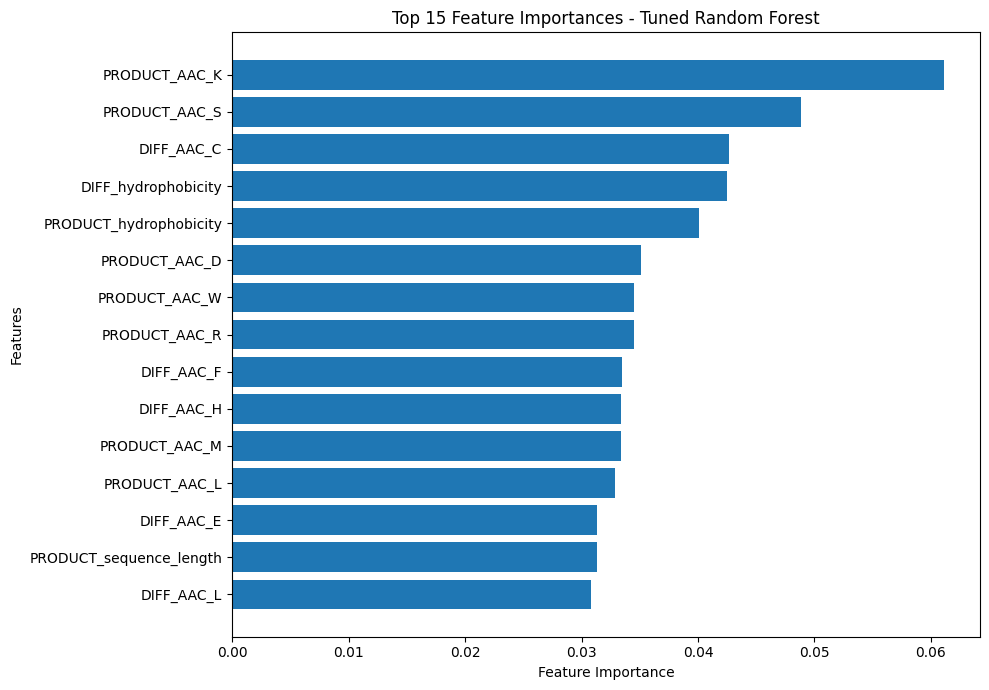

In [ ]:
# STEP 11: FEATURE IMPORTANCE ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

# Get tuned Random Forest model
rf_model = best_models["Random Forest"]

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": selected_features,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("Top 15 Important Features:")
display(feature_importance.head(15))

# Plot top 15 features
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Feature Importances - Tuned Random Forest")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 12: ERROR ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# Tuned Random Forest predictions
rf_model = best_models["Random Forest"]

y_pred_rf = rf_model.predict(X_test_selected)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Identify prediction errors
y_test_array = np.asarray(y_test)

false_positives = np.where(
    (y_test_array == 0) & (y_pred_rf == 1)
)[0]

false_negatives = np.where(
    (y_test_array == 1) & (y_pred_rf == 0)
)[0]

true_positives = np.where(
    (y_test_array == 1) & (y_pred_rf == 1)
)[0]

true_negatives = np.where(
    (y_test_array == 0) & (y_pred_rf == 0)
)[0]

print("\nPrediction Analysis:")
print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))
print("True Positives:", len(true_positives))
print("True Negatives:", len(true_negatives))

Confusion Matrix:
[[1120  380]
 [ 545  955]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.75      0.71      1500
           1       0.72      0.64      0.67      1500

    accuracy                           0.69      3000
   macro avg       0.69      0.69      0.69      3000
weighted avg       0.69      0.69      0.69      3000


Prediction Analysis:
False Positives: 380
False Negatives: 545
True Positives: 955
True Negatives: 1120


In [ ]:
# Find test dataset variables safely

print("Possible test dataset variables:")

for name, value in list(globals().copy().items()):
    if isinstance(value, pd.DataFrame):
        if "test" in name.lower():
            print(name, value.shape)

Possible test dataset variables:
X_test (3000, 46)
test_results_df (3, 6)


In [ ]:
# Inspect all existing DataFrames

for name, value in list(globals().copy().items()):
    if isinstance(value, pd.DataFrame):
        print("\nDataFrame:", name)
        print("Shape:", value.shape)
        print("Columns:", list(value.columns))


DataFrame: links
Shape: (10826054, 3)
Columns: ['protein1', 'protein2', 'combined_score']

DataFrame: positive_candidates
Shape: (282864, 6)
Columns: ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']

DataFrame: available
Shape: (6138, 6)
Columns: ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']

DataFrame: negatives
Shape: (1500, 3)
Columns: ['protein_A', 'protein_B', 'label']

DataFrame: combined
Shape: (3000, 3)
Columns: ['protein_A', 'protein_B', 'label']

DataFrame: data
Shape: (3000, 3)
Columns: ['protein_A', 'protein_B', 'label']

DataFrame: all_pairs
Shape: (20000, 3)
Columns: ['protein_A', 'protein_B', 'label']

DataFrame: protein_feature_df
Shape: (13917, 23)
Columns: ['AAC_A', 'AAC_C', 'AAC_D', 'AAC_E', 'AAC_F', 'AAC_G', 'AAC_H', 'AAC_I', 'AAC_K', 'AAC_L', 'AAC_M', 'AAC_N', 'AAC_P', 'AAC_Q', 'AAC_R', 'AAC_S', 'AAC_T', 'AAC_V', 'AAC_W', 'AAC_Y', 'sequence_length', 'molecular_weight', 'hydrophobicity']

DataFrame: X_tra

In [ ]:
# Find the original protein-pair dataset

for name, value in list(globals().copy().items()):
    if isinstance(value, pd.DataFrame):
        cols = list(value.columns)

        if any("protein1" in str(c).lower() for c in cols):
            print("\nDataset:", name)
            print("Shape:", value.shape)
            print("Columns:", cols)
            display(value.head(3))


Dataset: links
Shape: (10826054, 3)
Columns: ['protein1', 'protein2', 'combined_score']


,protein1,protein2,combined_score
0,9606.ENSP00000000233,9606.ENSP00000000412,200
1,9606.ENSP00000000233,9606.ENSP00000037243,178
2,9606.ENSP00000000233,9606.ENSP00000040663,226



Dataset: positive_candidates
Shape: (282864, 6)
Columns: ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']


,protein1,protein2,combined_score,protein_A,protein_B,label
6190749,9606.ENSP00000360242,9606.ENSP00000311032,999,9606.ENSP00000311032,9606.ENSP00000360242,1
9626959,9606.ENSP00000449328,9606.ENSP00000355315,999,9606.ENSP00000355315,9606.ENSP00000449328,1
7654291,9606.ENSP00000378974,9606.ENSP00000264110,999,9606.ENSP00000264110,9606.ENSP00000378974,1



Dataset: available
Shape: (6138, 6)
Columns: ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']


,protein1,protein2,combined_score,protein_A,protein_B,label
8468064,9606.ENSP00000398698,9606.ENSP00000365435,999,9606.ENSP00000365435,9606.ENSP00000398698,1
4674014,9606.ENSP00000338990,9606.ENSP00000324560,999,9606.ENSP00000324560,9606.ENSP00000338990,1
5380269,9606.ENSP00000352257,9606.ENSP00000307004,999,9606.ENSP00000307004,9606.ENSP00000352257,1


In [ ]:
# Find datasets containing protein pairs and labels

for name, value in list(globals().copy().items()):
    if isinstance(value, pd.DataFrame):

        cols = [str(c).lower() for c in value.columns]

        has_protein = (
            any("protein_a" in c or "protein1" in c for c in cols)
        )

        has_label = "label" in cols

        if has_protein and has_label:
            print("\nDataset:", name)
            print("Shape:", value.shape)
            print("Columns:", list(value.columns))


Dataset: positive_candidates
Shape: (282864, 6)
Columns: ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']

Dataset: available
Shape: (6138, 6)
Columns: ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']

Dataset: negatives
Shape: (1500, 3)
Columns: ['protein_A', 'protein_B', 'label']

Dataset: combined
Shape: (3000, 3)
Columns: ['protein_A', 'protein_B', 'label']

Dataset: data
Shape: (3000, 3)
Columns: ['protein_A', 'protein_B', 'label']

Dataset: all_pairs
Shape: (20000, 3)
Columns: ['protein_A', 'protein_B', 'label']


In [ ]:
print("Are combined and data identical?")
print(combined.equals(data))

print("\nCOMBINED dataset:")
display(combined.head())

print("\nDATA dataset:")
display(data.head())

print("\nTest labels:")
print(np.asarray(y_test)[:10])

print("\nDataset labels:")
print(data["label"].head(10).to_list())

Are combined and data identical?
False

COMBINED dataset:


,protein_A,protein_B,label
0,9606.ENSP00000423505,9606.ENSP00000458355,1
1,9606.ENSP00000433560,9606.ENSP00000498622,1
2,9606.ENSP00000342889,9606.ENSP00000489311,1
3,9606.ENSP00000346483,9606.ENSP00000368970,1
4,9606.ENSP00000343741,9606.ENSP00000491596,1



DATA dataset:


,protein_A,protein_B,label
0,9606.ENSP00000221665,9606.ENSP00000411145,0
1,9606.ENSP00000281701,9606.ENSP00000323046,1
2,9606.ENSP00000216133,9606.ENSP00000386193,0
3,9606.ENSP00000382140,9606.ENSP00000497876,1
4,9606.ENSP00000250784,9606.ENSP00000330393,0



Test labels:
[0 1 0 1 0 1 1 0 1 0]

Dataset labels:
[0, 1, 0, 1, 0, 1, 1, 0, 1, 0]


In [ ]:
print("Data shape:", data.shape)
print("Test labels shape:", np.asarray(y_test).shape)

print(
    "Do all labels match?",
    np.array_equal(data["label"].to_numpy(), np.asarray(y_test))
)

print("\nFirst 10 labels from data:")
print(data["label"].head(10).to_list())

print("\nFirst 10 test labels:")
print(np.asarray(y_test)[:10])

Data shape: (3000, 3)
Test labels shape: (3000,)
Do all labels match? True

First 10 labels from data:
[0, 1, 0, 1, 0, 1, 1, 0, 1, 0]

First 10 test labels:
[0 1 0 1 0 1 1 0 1 0]


In [ ]:
# STEP 15: IDENTIFY MISCLASSIFIED PROTEIN PAIRS

error_analysis = data.copy()

# Add actual and predicted labels
error_analysis["actual"] = np.asarray(y_test)
error_analysis["predicted"] = np.asarray(y_pred_rf)

# Classify prediction outcomes
conditions = [
    (error_analysis["actual"] == 1) &
    (error_analysis["predicted"] == 1),

    (error_analysis["actual"] == 0) &
    (error_analysis["predicted"] == 0),

    (error_analysis["actual"] == 0) &
    (error_analysis["predicted"] == 1),

    (error_analysis["actual"] == 1) &
    (error_analysis["predicted"] == 0)
]

choices = [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]

error_analysis["prediction_result"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

# Display counts
print("Prediction result counts:")
print(error_analysis["prediction_result"].value_counts())

# Extract incorrect predictions
misclassified = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
]

print("\nTotal misclassified pairs:", len(misclassified))

print("\nFalse Positive Pairs:")
display(
    misclassified[
        misclassified["prediction_result"] == "False Positive"
    ].head(10)
)

print("\nFalse Negative Pairs:")
display(
    misclassified[
        misclassified["prediction_result"] == "False Negative"
    ].head(10)
)

Prediction result counts:
prediction_result
True Negative     1120
True Positive      955
False Negative     545
False Positive     380
Name: count, dtype: int64

Total misclassified pairs: 925

False Positive Pairs:


,protein_A,protein_B,label,actual,predicted,prediction_result
4,9606.ENSP00000250784,9606.ENSP00000330393,0,0,1,False Positive
9,9606.ENSP00000249330,9606.ENSP00000484658,0,0,1,False Positive
23,9606.ENSP00000219345,9606.ENSP00000334928,0,0,1,False Positive
45,9606.ENSP00000211998,9606.ENSP00000358918,0,0,1,False Positive
46,9606.ENSP00000254101,9606.ENSP00000350698,0,0,1,False Positive
55,9606.ENSP00000216259,9606.ENSP00000415139,0,0,1,False Positive
70,9606.ENSP00000245414,9606.ENSP00000302537,0,0,1,False Positive
73,9606.ENSP00000215531,9606.ENSP00000228495,0,0,1,False Positive
76,9606.ENSP00000240185,9606.ENSP00000406052,0,0,1,False Positive
80,9606.ENSP00000223095,9606.ENSP00000254286,0,0,1,False Positive



False Negative Pairs:


,protein_A,protein_B,label,actual,predicted,prediction_result
5,9606.ENSP00000405222,9606.ENSP00000431926,1,1,0,False Negative
6,9606.ENSP00000378845,9606.ENSP00000424655,1,1,0,False Negative
8,9606.ENSP00000216416,9606.ENSP00000379097,1,1,0,False Negative
11,9606.ENSP00000287706,9606.ENSP00000307911,1,1,0,False Negative
12,9606.ENSP00000211998,9606.ENSP00000293379,1,1,0,False Negative
17,9606.ENSP00000291568,9606.ENSP00000291574,1,1,0,False Negative
20,9606.ENSP00000266542,9606.ENSP00000278407,1,1,0,False Negative
21,9606.ENSP00000300057,9606.ENSP00000386170,1,1,0,False Negative
22,9606.ENSP00000357622,9606.ENSP00000489770,1,1,0,False Negative
24,9606.ENSP00000159060,9606.ENSP00000254627,1,1,0,False Negative


In [ ]:
# STEP 16: PREDICTION CONFIDENCE ANALYSIS

# Get positive-class probabilities
y_prob_rf = rf_model.predict_proba(X_test_selected)[:, 1]

# Add probabilities to error analysis
error_analysis["prediction_probability"] = y_prob_rf

# Show most confident false positives
print("Top 10 confident False Positives:")

display(
    error_analysis[
        error_analysis["prediction_result"] == "False Positive"
    ].sort_values(
        by="prediction_probability",
        ascending=False
    ).head(10)
)

# Show most confident false negatives
print("\nTop 10 confident False Negatives:")

display(
    error_analysis[
        error_analysis["prediction_result"] == "False Negative"
    ].sort_values(
        by="prediction_probability",
        ascending=True
    ).head(10)
)

Top 10 confident False Positives:


,protein_A,protein_B,label,actual,predicted,prediction_result,prediction_probability
272,9606.ENSP00000223836,9606.ENSP00000296577,0,0,1,False Positive,0.866667
1796,9606.ENSP00000253363,9606.ENSP00000369989,0,0,1,False Positive,0.850000
2399,9606.ENSP00000206423,9606.ENSP00000364270,0,0,1,False Positive,0.823333
2465,9606.ENSP00000216446,9606.ENSP00000405965,0,0,1,False Positive,0.813333
1488,9606.ENSP00000196371,9606.ENSP00000264279,0,0,1,False Positive,0.810000
2877,9606.ENSP00000223836,9606.ENSP00000410689,0,0,1,False Positive,0.800000
1204,9606.ENSP00000196371,9606.ENSP00000373627,0,0,1,False Positive,0.793333
1150,9606.ENSP00000199320,9606.ENSP00000385205,0,0,1,False Positive,0.793333
1327,9606.ENSP00000250784,9606.ENSP00000346892,0,0,1,False Positive,0.790000
1910,9606.ENSP00000225235,9606.ENSP00000403172,0,0,1,False Positive,0.783333



Top 10 confident False Negatives:


,protein_A,protein_B,label,actual,predicted,prediction_result,prediction_probability
1934,9606.ENSP00000329471,9606.ENSP00000373696,1,1,0,False Negative,0.133333
2908,9606.ENSP00000276218,9606.ENSP00000459962,1,1,0,False Negative,0.136667
363,9606.ENSP00000320935,9606.ENSP00000497642,1,1,0,False Negative,0.140000
27,9606.ENSP00000243253,9606.ENSP00000306902,1,1,0,False Negative,0.140000
306,9606.ENSP00000321498,9606.ENSP00000484228,1,1,0,False Negative,0.146667
2422,9606.ENSP00000320935,9606.ENSP00000334100,1,1,0,False Negative,0.153333
1962,9606.ENSP00000248076,9606.ENSP00000323816,1,1,0,False Negative,0.166667
74,9606.ENSP00000276218,9606.ENSP00000350005,1,1,0,False Negative,0.170000
2473,9606.ENSP00000085219,9606.ENSP00000299727,1,1,0,False Negative,0.170000
1236,9606.ENSP00000253024,9606.ENSP00000335437,1,1,0,False Negative,0.183333


In [ ]:
# STEP 17: CONFIDENCE SUMMARY

confidence_summary = error_analysis.groupby(
    "prediction_result"
)["prediction_probability"].agg(
    ["mean", "min", "max", "count"]
).round(4)

print("Prediction Confidence Summary:")
display(confidence_summary)

Prediction Confidence Summary:


,mean,min,max,count
prediction_result,,,,
False Negative,0.3943,0.1333,0.5000,545
False Positive,0.5914,0.5033,0.8667,380
True Negative,0.3499,0.0633,0.5000,1120
True Positive,0.6658,0.5033,1.0000,955


In [ ]:
# STEP 18: FINAL MODEL COMPARISON

final_comparison_df = final_comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(
    final_comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original Random Forest,0.6860,0.7117,0.6253,0.6657,0.7621
1,Tuned Random Forest,0.6917,0.7154,0.6367,0.6737,0.7602
2,Tuned SVM,0.6910,0.7272,0.6113,0.6643,0.7578
3,Original Logistic Regression,0.6760,0.6897,0.6400,0.6639,0.7431
4,Tuned Logistic Regression,0.6713,0.6844,0.6360,0.6593,0.7429
5,Original SVM,0.6757,0.7047,0.6047,0.6509,0.7397


In [ ]:
print("Available dataset variables:\n")

for name, value in list(globals().copy().items()):
    if isinstance(value, pd.DataFrame):
        if any(word in name.lower() for word in ["train", "val", "test", "data"]):
            print(name, value.shape, list(value.columns))

Available dataset variables:

data (3000, 3) ['protein_A', 'protein_B', 'label']
X_train (14000, 46) ['DIFF_AAC_A', 'DIFF_AAC_C', 'DIFF_AAC_D', 'DIFF_AAC_E', 'DIFF_AAC_F', 'DIFF_AAC_G', 'DIFF_AAC_H', 'DIFF_AAC_I', 'DIFF_AAC_K', 'DIFF_AAC_L', 'DIFF_AAC_M', 'DIFF_AAC_N', 'DIFF_AAC_P', 'DIFF_AAC_Q', 'DIFF_AAC_R', 'DIFF_AAC_S', 'DIFF_AAC_T', 'DIFF_AAC_V', 'DIFF_AAC_W', 'DIFF_AAC_Y', 'DIFF_sequence_length', 'DIFF_molecular_weight', 'DIFF_hydrophobicity', 'PRODUCT_AAC_A', 'PRODUCT_AAC_C', 'PRODUCT_AAC_D', 'PRODUCT_AAC_E', 'PRODUCT_AAC_F', 'PRODUCT_AAC_G', 'PRODUCT_AAC_H', 'PRODUCT_AAC_I', 'PRODUCT_AAC_K', 'PRODUCT_AAC_L', 'PRODUCT_AAC_M', 'PRODUCT_AAC_N', 'PRODUCT_AAC_P', 'PRODUCT_AAC_Q', 'PRODUCT_AAC_R', 'PRODUCT_AAC_S', 'PRODUCT_AAC_T', 'PRODUCT_AAC_V', 'PRODUCT_AAC_W', 'PRODUCT_AAC_Y', 'PRODUCT_sequence_length', 'PRODUCT_molecular_weight', 'PRODUCT_hydrophobicity']
X_val (3000, 46) ['DIFF_AAC_A', 'DIFF_AAC_C', 'DIFF_AAC_D', 'DIFF_AAC_E', 'DIFF_AAC_F', 'DIFF_AAC_G', 'DIFF_AAC_H', 'DIFF_AAC

In [ ]:
print("Protein pair dataset variables:")

for name, value in list(globals().copy().items()):
    if isinstance(value, pd.DataFrame):
        cols = list(value.columns)
        if "protein_A" in cols and "protein_B" in cols:
            print(name, value.shape, cols)

Protein pair dataset variables:
positive_candidates (282864, 6) ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']
available (6138, 6) ['protein1', 'protein2', 'combined_score', 'protein_A', 'protein_B', 'label']
negatives (1500, 3) ['protein_A', 'protein_B', 'label']
combined (3000, 3) ['protein_A', 'protein_B', 'label']
data (3000, 3) ['protein_A', 'protein_B', 'label']
all_pairs (20000, 3) ['protein_A', 'protein_B', 'label']
error_analysis (3000, 7) ['protein_A', 'protein_B', 'label', 'actual', 'predicted', 'prediction_result', 'prediction_probability']
misclassified (925, 6) ['protein_A', 'protein_B', 'label', 'actual', 'predicted', 'prediction_result']


In [ ]:
print("Scaler fitted samples:", scaler.n_samples_seen_)
print("Training samples:", X_train.shape[0])
print("Selected features:", len(selected_features))

Scaler fitted samples: 14000
Training samples: 14000
Selected features: 30


In [ ]:
print("SVM Cross-Validation Details")
print("CV strategy:", type(search.cv).__name__)
print("CV folds:", search.cv)
print("Best parameters:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))

SVM Cross-Validation Details
CV strategy: int
CV folds: 3
Best parameters: {'kernel': 'rbf', 'gamma': 0.01, 'C': 1}
Best CV ROC-AUC: 0.7553


In [ ]:
print("DATASET VARIABLES:")

for name, value in list(globals().copy().items()):
    if isinstance(value, pd.DataFrame):
        cols = list(value.columns)
        if "protein_A" in cols and "protein_B" in cols:
            print(name, value.shape)

print("\nPROTEIN SPLIT VARIABLES:")

for name, value in list(globals().copy().items()):
    if isinstance(value, (set, frozenset)) and any(
        word in name.lower() for word in ["train", "val", "test"]
    ):
        print(name, len(value))

DATASET VARIABLES:
positive_candidates (282864, 6)
available (6138, 6)
negatives (1500, 3)
combined (3000, 3)
data (3000, 3)
all_pairs (20000, 3)
error_analysis (3000, 7)
misclassified (925, 6)

PROTEIN SPLIT VARIABLES:


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file in ["ppi_train.csv", "ppi_validation.csv", "ppi_test.csv"]:
            print(os.path.join(root, file))

/content/ppi_validation.csv
/content/ppi_train.csv
/content/ppi_test.csv


In [ ]:
# STEP 19: DATA LEAKAGE VERIFICATION

ppi_train = pd.read_csv("/content/ppi_train.csv")
ppi_validation = pd.read_csv("/content/ppi_validation.csv")
ppi_test = pd.read_csv("/content/ppi_test.csv")

train_proteins = set(ppi_train["protein_A"]) | set(ppi_train["protein_B"])
val_proteins = set(ppi_validation["protein_A"]) | set(ppi_validation["protein_B"])
test_proteins = set(ppi_test["protein_A"]) | set(ppi_test["protein_B"])

print("Train proteins:", len(train_proteins))
print("Validation proteins:", len(val_proteins))
print("Test proteins:", len(test_proteins))

print("\nPROTEIN OVERLAP:")
print("Train–Validation:", len(train_proteins & val_proteins))
print("Train–Test:", len(train_proteins & test_proteins))
print("Validation–Test:", len(val_proteins & test_proteins))

Train proteins: 9925
Validation proteins: 1978
Test proteins: 2014

PROTEIN OVERLAP:
Train–Validation: 0
Train–Test: 0
Validation–Test: 0


In [ ]:
import pandas as pd

final_test_results = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Original Random Forest",
        "Original SVM",
        "Tuned Logistic Regression",
        "Tuned Random Forest",
        "Tuned SVM"
    ],
    "Accuracy": [0.6760, 0.6860, 0.6757, 0.6713, 0.6917, 0.6910],
    "Precision": [0.6897, 0.7117, 0.7047, 0.6844, 0.7154, 0.7272],
    "Recall": [0.6400, 0.6253, 0.6047, 0.6360, 0.6367, 0.6113],
    "F1-Score": [0.6639, 0.6657, 0.6509, 0.6593, 0.6737, 0.6643],
    "ROC-AUC": [0.7431, 0.7621, 0.7397, 0.7429, 0.7602, 0.7578]
})

print("FINAL TEST PERFORMANCE COMPARISON")
display(
    final_test_results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}",
        "ROC-AUC": "{:.4f}"
    })
)

FINAL TEST PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Original Logistic Regression,67.60%,68.97%,64.00%,66.39%,0.7431
1,Original Random Forest,68.60%,71.17%,62.53%,66.57%,0.7621
2,Original SVM,67.57%,70.47%,60.47%,65.09%,0.7397
3,Tuned Logistic Regression,67.13%,68.44%,63.60%,65.93%,0.7429
4,Tuned Random Forest,69.17%,71.54%,63.67%,67.37%,0.7602
5,Tuned SVM,69.10%,72.72%,61.13%,66.43%,0.7578


In [ ]:
print("trained_models:", "trained_models" in globals())
print("best_models:", "best_models" in globals())

trained_models: True
best_models: True


In [ ]:
for var in [
    "test_results_df",
    "six_model_test_results",
    "results_df",
    "y_test",
    "X_test_selected",
    "selected_features",
    "rf_importance"
]:
    print(var, ":", var in globals())

test_results_df : True
six_model_test_results : False
results_df : True
y_test : True
X_test_selected : True
selected_features : True
rf_importance : False


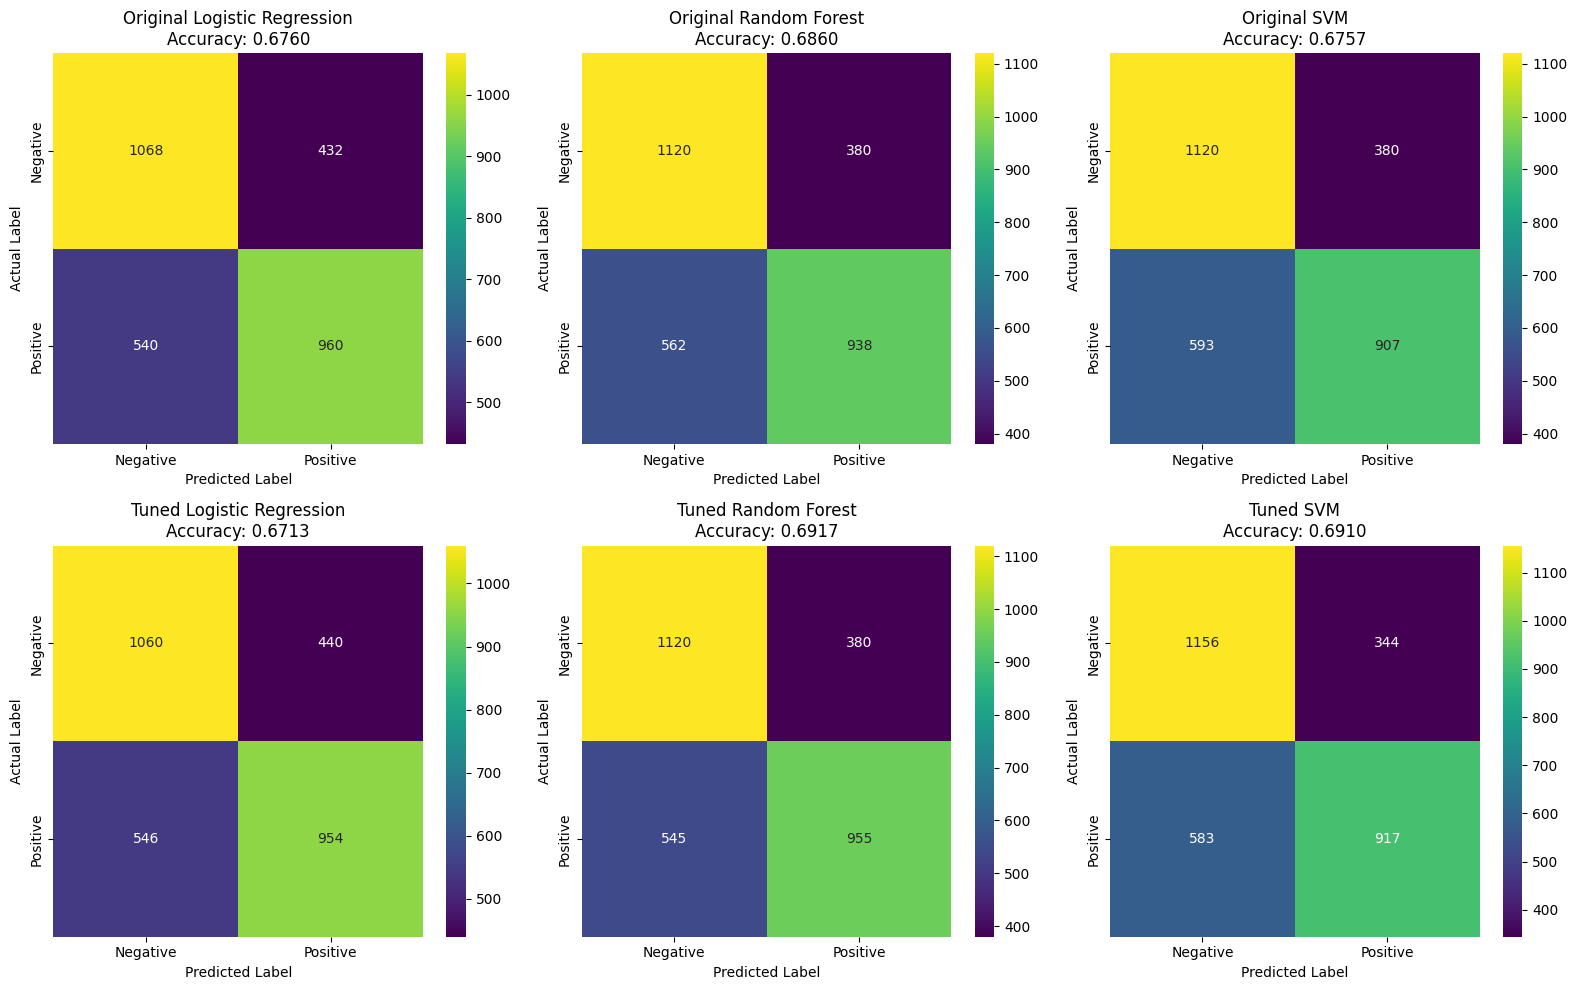


CONFUSION MATRIX VALUES

Original Logistic Regression
TN: 1068
FP: 432
FN: 540
TP: 960

Original Random Forest
TN: 1120
FP: 380
FN: 562
TP: 938

Original SVM
TN: 1120
FP: 380
FN: 593
TP: 907

Tuned Logistic Regression
TN: 1060
FP: 440
FN: 546
TP: 954

Tuned Random Forest
TN: 1120
FP: 380
FN: 545
TP: 955

Tuned SVM
TN: 1156
FP: 344
FN: 583
TP: 917


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import confusion_matrix, accuracy_score

# Combine original and tuned models
all_models = {
    "Original Logistic Regression": trained_models["Logistic Regression"],
    "Original Random Forest": trained_models["Random Forest"],
    "Original SVM": trained_models["SVM"],

    "Tuned Logistic Regression": best_models["Logistic Regression"],
    "Tuned Random Forest": best_models["Random Forest"],
    "Tuned SVM": best_models["SVM"]
}

# Store confusion matrices and test accuracies
confusion_results = {}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(all_models.items()):

    # Predict using the SAME held-out test dataset
    y_pred = model.predict(X_test_selected)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Store results
    confusion_results[name] = cm

    # Calculate accuracy for verification
    acc = accuracy_score(y_test, y_pred)

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="viridis",
        cbar=True,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[i]
    )

    axes[i].set_title(f"{name}\nAccuracy: {acc:.4f}")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Print numerical values
print("\nCONFUSION MATRIX VALUES")

for name, cm in confusion_results.items():
    tn, fp, fn, tp = cm.ravel()

    print(f"\n{name}")
    print(f"TN: {tn}")
    print(f"FP: {fp}")
    print(f"FN: {fn}")
    print(f"TP: {tp}")